# Paper Example 4: Measured Tritium in the Missouri River

This notebook walks through Example 4 of the PyTracerLab paper, which applies
PyTracerLab to measured data: 35 tritium concentrations measured in the Missouri
River (1963-1997) from Example 3 of TracerLPM (Jurgens et al., 2012), with the tritium
input time series of the same example. The data are used as distributed with
TracerLPM.

As in TracerLPM, river water is a binary mixture of

- groundwater discharge (exponential model unit) and
- runoff with zero travel time, i.e., with the tritium input at the time of sampling
  (piston flow model unit with a mean travel time of 0).

The mean travel time of the groundwater and the mixing fraction are calibrated. The
model is the same as in Listing 1 of the paper
([`listing_1.py`](https://github.com/iGW-TU-Dresden/PyTracerLab/blob/main/docs/examples/paper/listing_1.py)). The script
[`example_4.py`](https://github.com/iGW-TU-Dresden/PyTracerLab/blob/main/docs/examples/paper/example_4.py) produces the figure and numbers of the paper.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize

import PyTracerLab as lab

## 1. Data

The tritium input has a yearly resolution (1850-2020), and each sample is dated
1 July of its year. The input file `tritium_input_monthly.csv` repeats each yearly
value for every month of the year, which is the step function TracerLPM uses for
yearly input. With monthly time steps, the sampling dates fall on a time step; with
yearly time steps, the samples would be shifted by half a year, which matters on the
steep limbs of the bomb peak. The third file holds TracerLPM's simulation at its
best fit (mean travel time 6.8 yr, groundwater fraction 0.56).

In [2]:
inp = lab.read_series("tritium_input_monthly.csv")
obs = lab.read_series("tritium_observations_monthly.csv", align_to=inp)
tlpm = lab.read_series("example_4_tracerlpm.csv", align_to=inp)
o = obs.values.ravel()
idx = np.where(np.isfinite(o))[0]
t = np.array([d.year + (d.month - 1) / 12 for d in inp.times])
print(len(inp), "monthly time steps,", len(idx), "observations")

2052 monthly time steps, 35 observations


## 2. Model

The steady-state input of 6 TU describes the tritium concentration of water that
recharged before 1850, as in TracerLPM.

In [3]:
m = lab.Model(
    dt=1 / 12,
    lambda_=lab.decay_constant("Tritium"),
    input_series=inp.values,
    target_series=obs.values,
    steady_state_input=6.0,
    time_steps=inp.times,
)
m.add_unit(lab.EMUnit(mtt=5.0), fraction=0.5, prefix="gw", bounds=[(0.5, 50.0)])
m.add_unit(lab.PMUnit(mtt=0.0), fraction=0.5, prefix="runoff")
m.set_fixed("runoff.mtt")
m.set_fixed("gw.fraction", False)  # calibrate the mixing fraction
keys = m.param_keys(free_only=True)
print("Free parameters:", keys)

Free parameters: ['gw.fraction', 'gw.mtt']


## 3. Comparison with TracerLPM

First, PyTracerLab is run with TracerLPM's best-fit parameters and compared with
TracerLPM's simulation. Second, TracerLPM's objective function (sum of the absolute
relative errors) is minimised with PyTracerLab simulations; any objective can be
built from `Model.simulate`.

In [4]:
TRACERLPM = {"gw.mtt": 6.8, "gw.fraction": 0.56}


def simulate_at(values):
    for key, val in values.items():
        m.set_param(key, val)
    return m.simulate()


def tracerlpm_objective(values):
    sim = simulate_at(values)
    return float(np.sum(np.abs(sim[idx] - o[idx]) / o[idx]))


ref = tlpm.values.ravel()[idx]
diff = simulate_at(TRACERLPM)[idx] - ref
obj_tlpm = tracerlpm_objective(TRACERLPM)
print(f"At TracerLPM's best fit: max |PyTracerLab - TracerLPM| = {np.abs(diff).max():.3f} TU "
      f"({100 * np.abs(diff / ref).max():.2f} %)")


def f(p):
    return tracerlpm_objective(dict(zip(keys, p)))


r = optimize.differential_evolution(f, m.get_bounds(free_only=True), seed=1, tol=1e-8, maxiter=1000)
r = optimize.minimize(f, r.x, method="Nelder-Mead", options={"xatol": 1e-6, "fatol": 1e-10})
print(f"TracerLPM's objective: {obj_tlpm:.4f} at TracerLPM's best fit, "
      f"{r.fun:.4f} at {dict(zip(keys, np.round(r.x, 3).tolist()))}")

At TracerLPM's best fit: max |PyTracerLab - TracerLPM| = 0.637 TU (0.05 %)


TracerLPM's objective: 4.3775 at TracerLPM's best fit, 4.3754 at {'gw.fraction': 0.564, 'gw.mtt': 6.683}


## 4. Calibration with Measurement Uncertainty

Measurement uncertainties are not available for these data. A relative uncertainty
of 20 % is assumed, which corresponds to the root mean square of the relative
residuals of the best fit. Differential evolution gives the best fit, DREAM the
posterior distribution.

In [5]:
SIGMA_REL = 0.2
solver = lab.Solver(m)
de_x, de_sim = solver.differential_evolution(sigma_rel=SIGMA_REL, random_state=42, maxiter=10000)
print("DE:", {k: round(float(de_x[k]), 3) for k in keys})

dream = solver.dream_sample(n_samples=2000, burn_in=2000, n_chains=8, cr=[0.25, 0.5, 0.75, 1.0],
                            sigma_rel=SIGMA_REL, return_sim=True, random_state=42)
print("R-hat:", {k: round(float(v), 3) for k, v in dream["gelman_rubin"].items()},
      "| outlier chains moved:", dream["n_outlier_resets"])
s = dream["samples"]
for i, k in enumerate(dream["param_names"]):
    q = np.quantile(s[:, i], [0.01, 0.5, 0.99])
    print(f"{k:12s} median {q[1]:6.3f}  [1-99 %: {q[0]:.3f}, {q[2]:.3f}]")
print("Correlation of the two parameters:", round(np.corrcoef(s.T)[0, 1], 3))

DE: {'gw.fraction': 0.557, 'gw.mtt': 6.402}


R-hat: {'gw.fraction': 1.009, 'gw.mtt': 1.009} | outlier chains moved: 1
gw.fraction  median  0.554  [1-99 %: 0.390, 0.765]
gw.mtt       median  6.403  [1-99 %: 4.162, 9.690]
Correlation of the two parameters: -0.787


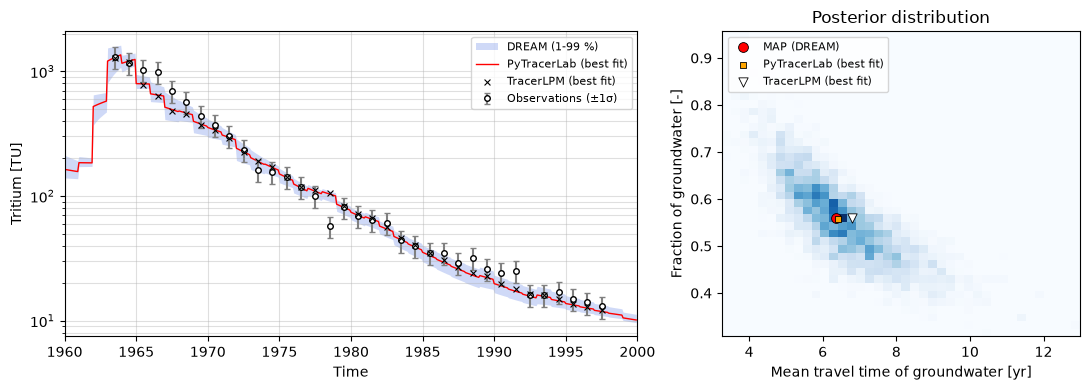

In [6]:
w = (t >= 1960) & (t < 2000)
band = np.quantile(dream["sims"].reshape(-1, len(t)), [0.01, 0.99], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].fill_between(t[w], band[0, w], band[1, w], color="royalblue", alpha=0.25, lw=0, label="DREAM (1-99 %)")
ax[0].plot(t[w], de_sim[w], c="red", lw=1.0, label="PyTracerLab (best fit)")
ax[0].scatter(t[idx], ref, marker="x", c="k", s=18, lw=0.8, zorder=50, label="TracerLPM (best fit)")
ax[0].errorbar(t[idx], o[idx], yerr=SIGMA_REL * o[idx], fmt="o", mfc="w", mec="k", ecolor="grey", ms=4,
               capsize=2, zorder=40, label="Observations (±1σ)")
ax[0].set(yscale="log", xlim=(1960, 2000), xlabel="Time", ylabel="Tritium [TU]")
ax[0].grid(True, which="both", alpha=0.4)
ax[0].legend(fontsize=8)

i_m, i_f = dream["param_names"].index("gw.mtt"), dream["param_names"].index("gw.fraction")
ax[1].hist2d(s[:, i_m], s[:, i_f], bins=40, cmap="Blues")
for values, style in (
    (dream["posterior_map"], dict(marker="o", c="r", s=50, label="MAP (DREAM)")),
    (de_x, dict(marker="s", c="orange", s=25, label="PyTracerLab (best fit)")),
    (TRACERLPM, dict(marker="v", c="w", s=45, label="TracerLPM (best fit)")),
):
    ax[1].scatter(values["gw.mtt"], values["gw.fraction"], edgecolor="k", lw=0.6, zorder=10, **style)
ax[1].set(xlabel="Mean travel time of groundwater [yr]", ylabel="Fraction of groundwater [-]",
          title="Posterior distribution")
ax[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

The two parameters are strongly negatively correlated: a larger fraction of
groundwater with a shorter mean travel time explains the observations about as well
as a smaller fraction with a longer mean travel time. Most of the misfit results
from a single sample (1978).

## Further Reading

- The user guide explains mixing fractions (when a fraction can be calibrated) and
  the measurement uncertainty options.